# Airline Loyalty Churn: Retention Prioritization

**Business question:** Which airline loyalty members are most likely to cancel in the near future, and which high-value customers should the retention team contact first?

The objective is not only to predict churn, but to help the airline prioritize limited retention offers for customers with the highest churn risk and customer value.

This is a retrospective portfolio project using historical cancellation labels. Results and ROI figures are illustrative, not a live airline forecast.

**Prediction setup:** stand at a snapshot date of **31 December 2017**, use only information known by then, and predict which active members cancel during **2018**.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
    roc_auc_score, average_precision_score, precision_recall_curve,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
)

import warnings
from sklearn.exceptions import UndefinedMetricWarning

# KNN may flag no churners at 0.50; its precision is then reported as 0 without a warning.
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## Data
Load the two Maven Analytics CSV files from `DATA`, the notebook folder, or upload them when running in Colab.

In [3]:
required_files = ["Customer Flight Activity.csv", "Customer Loyalty History.csv"]
search_dirs = [Path.cwd(), Path("DATA"), Path("../DATA")]
data_paths = {
    filename: next(
        (folder / filename for folder in search_dirs if (folder / filename).is_file()),
        None,
    )
    for filename in required_files
}
missing_files = [filename for filename, path in data_paths.items() if path is None]

if missing_files:
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(
            "Add both Maven Analytics CSVs to DATA (or the notebook folder) before running. "
            f"Missing: {', '.join(missing_files)}"
        ) from exc
    uploaded = files.upload()
    not_uploaded = [filename for filename in missing_files if filename not in uploaded]
    if not_uploaded:
        raise FileNotFoundError(
            f"Upload the required dataset files: {', '.join(not_uploaded)}"
        )
    for filename in missing_files:
        data_paths[filename] = Path(filename)

flight_df = pd.read_csv(data_paths[required_files[0]])
loyalty_df = pd.read_csv(data_paths[required_files[1]])

## Cleaning
Check data quality, remove duplicate records, and fix invalid values.

In [4]:
print("Flight data shape:", flight_df.shape)
print("Loyalty data shape:", loyalty_df.shape)
loyalty_df.head(3)

Flight data shape: (392936, 8)
Loyalty data shape: (16737, 16)


,Loyalty Number,Country,Province,City,Postal Code,Gender,Education,Salary,Marital Status,Loyalty Card,CLV,Enrollment Type,Enrollment Year,Enrollment Month,Cancellation Year,Cancellation Month
0,480934,Canada,Ontario,Toronto,M2Z 4K1,Female,Bachelor,83236.0,Married,Star,3839.14,Standard,2016,2,NaN,NaN
1,549612,Canada,Alberta,Edmonton,T3G 6Y6,Male,College,NaN,Divorced,Star,3839.61,Standard,2016,3,NaN,NaN
2,429460,Canada,British Columbia,Vancouver,V6E 3D9,Male,College,NaN,Single,Star,3839.75,Standard,2014,7,2018.0,1.0


In [5]:
flight_missing = flight_df.isna().sum().rename("Flight activity")
loyalty_missing = loyalty_df.isna().sum().rename("Loyalty history")
missing_summary = pd.concat([flight_missing, loyalty_missing], axis=1).fillna(0).astype(int)
missing_summary = missing_summary.loc[missing_summary.gt(0).any(axis=1)]
display(missing_summary)

,Flight activity,Loyalty history
Salary,0,4238
Cancellation Year,0,14670
Cancellation Month,0,14670


Missing `Cancellation Year/Month` is expected (the member is still active). Missing `Salary` is imputed later inside the model pipeline.

In [6]:
flight_duplicates = int(flight_df.duplicated().sum())
flight_df = flight_df.drop_duplicates()

# Some members still have several different rows for the same month; add them into one monthly record.
repeat_months = int(flight_df.duplicated(["Loyalty Number", "Year", "Month"]).sum())
flight_df = flight_df.groupby(["Loyalty Number", "Year", "Month"], as_index=False).sum()

# A salary cannot be negative, so treat those values as missing.
negative_salaries = int((loyalty_df["Salary"] < 0).sum())
loyalty_df.loc[loyalty_df["Salary"] < 0, "Salary"] = np.nan

print(f"Removed {flight_duplicates:,} exact duplicate flight rows.")
print(f"Combined {repeat_months:,} extra rows for the same member and month.")
print(f"Set {negative_salaries} negative salaries to missing.")

Removed 1,922 exact duplicate flight rows.
Combined 1,949 extra rows for the same member and month.
Set 20 negative salaries to missing.


## Avoiding target leakage
Flight activity only covers **2017–2018**, while cancellations go back to **2013**. If every cancelled member is labelled as churn and we total up their flights, the model learns that people who already left stopped flying. That looks like high accuracy but predicts nothing useful.

In [7]:
cancel_years = loyalty_df["Cancellation Year"].value_counts().sort_index().astype(int)
display(cancel_years.rename("Cancellations").to_frame())

month_index = lambda year, month: year * 12 + month
cancelled = loyalty_df.dropna(subset=["Cancellation Year"])
activity = flight_df.merge(
    cancelled[["Loyalty Number", "Cancellation Year", "Cancellation Month"]], on="Loyalty Number"
)
after_cancel = activity[
    month_index(activity["Year"], activity["Month"])
    > month_index(activity["Cancellation Year"], activity["Cancellation Month"])
]
print(f"Monthly rows after a member cancelled: {len(after_cancel):,}")
print(f"Flights recorded in those rows: {after_cancel['Total Flights'].sum():,}")

,Cancellations
Cancellation Year,
2013.0,43
2014.0,181
2015.0,265
2016.0,427
2017.0,506
2018.0,645


Monthly rows after a member cancelled: 33,988
Flights recorded in those rows: 0


**Insight:** Every month after a cancellation shows zero flights, and many churners cancelled before the flight data starts. Low activity is partly a *result* of churn, not only a warning sign.

**Fix:** Pick a snapshot date. Build features only from activity **up to the snapshot**, keep only members who were **active at the snapshot**, and label churn as **cancelling after it**.

In [8]:
SNAPSHOT_YEAR, SNAPSHOT_MONTH = 2017, 12
snapshot = month_index(SNAPSHOT_YEAR, SNAPSHOT_MONTH)

enrolled = month_index(loyalty_df["Enrollment Year"], loyalty_df["Enrollment Month"])
cancelled_at = month_index(loyalty_df["Cancellation Year"], loyalty_df["Cancellation Month"])

# Active at the snapshot: enrolled on or before it and not yet cancelled.
active_at_snapshot = (enrolled <= snapshot) & ~(cancelled_at <= snapshot)
members = loyalty_df[active_at_snapshot].copy()
members["tenure_months"] = snapshot - enrolled[active_at_snapshot]
members["Churned"] = cancelled_at[active_at_snapshot].notna().astype(int)  # cancelled during 2018

print(f"Members active on {SNAPSHOT_MONTH}/{SNAPSHOT_YEAR}: {len(members):,}")
display(
    members["Churned"]
    .value_counts(normalize=True)
    .rename(index={0: "Stayed", 1: "Cancelled in 2018"})
    .rename("Share")
    .to_frame()
    .round(3)
)

Members active on 12/2017: 12,305


,Share
Churned,
Stayed,0.961
Cancelled in 2018,0.039


**Insight:** Only about 4% of active members cancel in the next year. A model that predicts "nobody churns" would be 96% accurate, so **accuracy is not a useful metric here**. We focus on recall, precision, and PR-AUC instead.

## Feature Engineering
Turn 2017 monthly activity into one row per member, including recency and trend signals.

In [9]:
history = flight_df[flight_df["Year"] == SNAPSHOT_YEAR]
by_member = history.groupby("Loyalty Number")

flight_features = by_member.agg(
    flights_2017=("Total Flights", "sum"),
    distance_2017=("Distance", "sum"),
    points_accumulated_2017=("Points Accumulated", "sum"),
    points_redeemed_2017=("Points Redeemed", "sum"),
    redeem_cost_2017=("Dollar Cost Points Redeemed", "sum"),
)
flown = history[history["Total Flights"] > 0].groupby("Loyalty Number")
flight_features["months_flown_2017"] = flown["Month"].nunique()
flight_features["months_since_last_flight"] = SNAPSHOT_MONTH - flown["Month"].max()
flight_features["flights_q4_2017"] = history[history["Month"] >= 10].groupby("Loyalty Number")["Total Flights"].sum()
flight_features["flights_h1_2017"] = history[history["Month"] <= 6].groupby("Loyalty Number")["Total Flights"].sum()
flight_features["flights_h2_2017"] = history[history["Month"] > 6].groupby("Loyalty Number")["Total Flights"].sum()
flight_features = flight_features.reset_index()

flight_features["points_redeem_ratio"] = (
    flight_features["points_redeemed_2017"]
    / flight_features["points_accumulated_2017"].replace(0, np.nan)
)
flight_features["flight_trend"] = flight_features["flights_h2_2017"] - flight_features["flights_h1_2017"]

df = members.merge(flight_features, on="Loyalty Number", how="left")
# Members who never flew in 2017 have no rows: treat counts as 0 and recency as the full year.
df["months_since_last_flight"] = df["months_since_last_flight"].fillna(12)
activity_cols = flight_features.columns.drop(["Loyalty Number", "months_since_last_flight"])
df[activity_cols] = df[activity_cols].fillna(0)

df[["Loyalty Number", "tenure_months", "flights_2017", "months_since_last_flight", "flight_trend", "Churned"]].head(3)

,Loyalty Number,tenure_months,flights_2017,months_since_last_flight,flight_trend,Churned
0,480934,22,18,0.0,0,0
1,549612,21,31,1.0,1,0
2,429460,41,16,1.0,-2,1


## EDA
Check whether 2017 activity relates to churn in 2018.

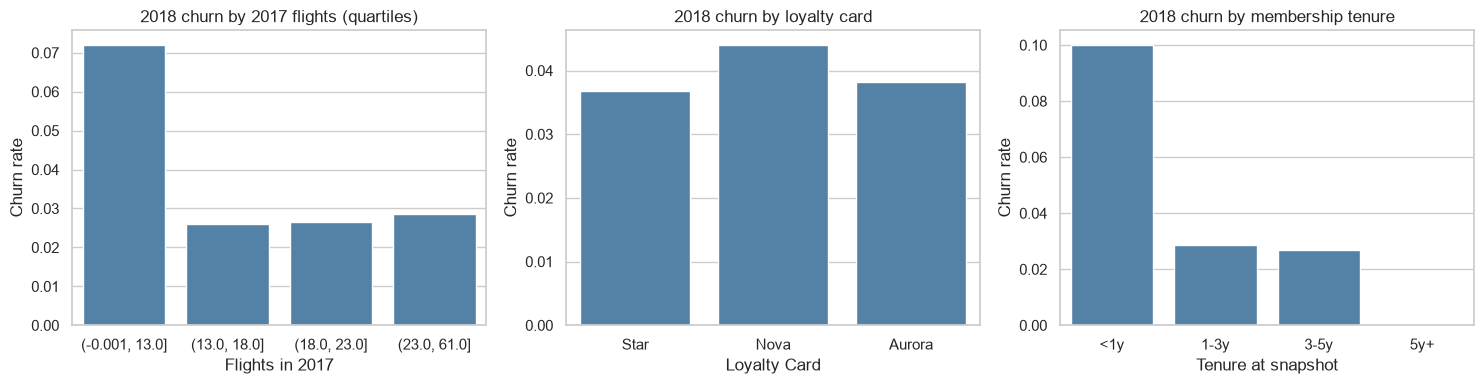

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df["flight_band"] = pd.qcut(df["flights_2017"], q=4, duplicates="drop")
sns.barplot(x="flight_band", y="Churned", data=df, ax=axes[0], color="steelblue", errorbar=None)
axes[0].set(title="2018 churn by 2017 flights (quartiles)", xlabel="Flights in 2017", ylabel="Churn rate")

sns.barplot(x="Loyalty Card", y="Churned", data=df, ax=axes[1], color="steelblue", errorbar=None,
            order=["Star", "Nova", "Aurora"])
axes[1].set(title="2018 churn by loyalty card", ylabel="Churn rate")

df["tenure_band"] = pd.cut(df["tenure_months"], bins=[-1, 12, 36, 60, 120], labels=["<1y", "1-3y", "3-5y", "5y+"])
sns.barplot(x="tenure_band", y="Churned", data=df, ax=axes[2], color="steelblue", errorbar=None)
axes[2].set(title="2018 churn by membership tenure", xlabel="Tenure at snapshot", ylabel="Churn rate")
plt.tight_layout()
plt.show()
df = df.drop(columns=["flight_band", "tenure_band"])

**Insight:** The lowest quarter of 2017 flyers cancel at about 7% in 2018, against about 3% for everyone else. That is a real gap, but much smaller than the 22.8% vs 1.9% the leaky version showed. Members in their **first year** cancel at about 10%, while card tier makes little difference.

**Business action:** Onboarding and early-tenure engagement look like the clearest retention levers.

## Modeling
Drop identifiers, leaky date columns, and redundant location fields. Then compare five models with 5-fold cross-validation **on the training set only**. The test set stays untouched until the final check.

In [11]:
drop_cols = [
    "Loyalty Number",                          # identifier, not a behaviour
    "Country",                                 # only one value (Canada)
    "City", "Postal Code",                     # repeat Province with many sparse categories
    "Enrollment Year", "Enrollment Month",     # replaced by tenure_months
    "Cancellation Year", "Cancellation Month", # these define the target: leakage
]
X = df.drop(columns=drop_cols + ["Churned"])
y = df["Churned"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train), "| churners:", int(y_train.sum()))
print("Test rows:", len(X_test), "| churners:", int(y_test.sum()))

Training rows: 9844 | churners: 389
Test rows: 2461 | churners: 97


In [12]:
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.columns.difference(num_cols).tolist()

preprocessor = ColumnTransformer(transformers=[
    ("num", Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),   # needed for Logistic Regression, KNN and SVM
    ]), num_cols),
    ("cat", Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), cat_cols),
])

candidates = {
    "Baseline (always 'stay')": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "KNN": KNeighborsClassifier(n_neighbors=25),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1,
    ),
    # SVC has no predict_proba of its own; calibration turns its scores into probabilities.
    "SVM (RBF)": CalibratedClassifierCV(SVC(class_weight="balanced", random_state=RANDOM_STATE), ensemble=False),
}
make_pipeline = lambda model: Pipeline(steps=[("preprocess", preprocessor), ("model", model)])

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "Accuracy": "accuracy",
    "Recall": "recall",
    "Precision": "precision",
    "F1": "f1",
    "ROC-AUC": "roc_auc",
    "PR-AUC": "average_precision",
}
cv_rows = {}
for name, model in candidates.items():
    scores = cross_validate(make_pipeline(model), X_train, y_train, cv=cv, scoring=scoring)
    cv_rows[name] = {metric: scores[f"test_{metric}"].mean() for metric in scoring}
cv_results = pd.DataFrame(cv_rows).T.sort_values("PR-AUC", ascending=False)
display(cv_results.round(3))
print(f"Churn base rate (PR-AUC of random guessing): {y_train.mean():.3f}")

,Accuracy,Recall,Precision,F1,ROC-AUC,PR-AUC
Random Forest,0.899,0.306,0.142,0.194,0.709,0.108
Logistic Regression,0.680,0.591,0.071,0.127,0.695,0.101
SVM (RBF),0.960,0.000,0.000,0.000,0.670,0.084
KNN,0.960,0.000,0.000,0.000,0.641,0.073
Baseline (always 'stay'),0.960,0.000,0.000,0.000,0.500,0.040


Churn base rate (PR-AUC of random guessing): 0.040


**How to read this table**
- The baseline scores ~96% accuracy while catching zero churners, which is why accuracy is misleading here.
- **PR-AUC** is the main ranking metric for a rare outcome. Random guessing scores the churn rate (~0.04).
- KNN and SVM do not use `class_weight` the same way, or need probability calibration, so their default 0.50 recall is low. Compare them on ROC-AUC and PR-AUC.
- Linear *regression* is not used: churn is a yes/no outcome, so logistic regression is the correct linear model.

In [14]:
model_names = [name for name in cv_results.index if not name.startswith("Baseline")]
best_name = cv_results.loc[model_names, "PR-AUC"].idxmax()
best_model = make_pipeline(candidates[best_name])
print(f"Selected on cross-validated PR-AUC: {best_name}")

Selected on cross-validated PR-AUC: Random Forest


## Choosing a decision threshold
The default 0.50 cut-off is arbitrary, especially with `class_weight="balanced"`. Choose the threshold from **out-of-fold training predictions** (never from the test set). F2 weights recall twice as much as precision, because missing a churner usually costs more than one extra offer.

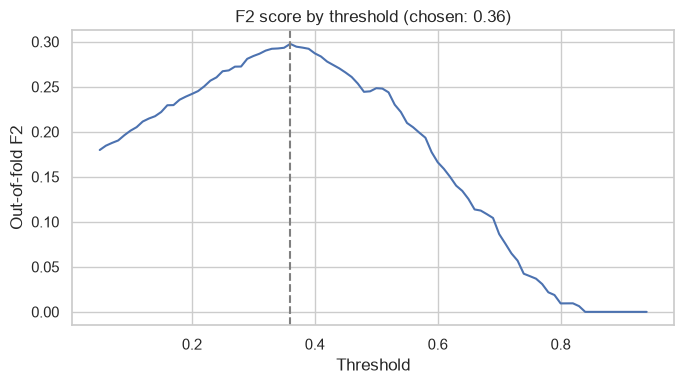

In [15]:
oof_prob = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
thresholds = np.round(np.arange(0.05, 0.95, 0.01), 2)
f2_by_threshold = [fbeta_score(y_train, oof_prob >= t, beta=2, zero_division=0) for t in thresholds]
chosen_threshold = float(thresholds[int(np.argmax(f2_by_threshold))])

plt.figure(figsize=(7, 4))
plt.plot(thresholds, f2_by_threshold)
plt.axvline(chosen_threshold, linestyle="--", color="gray")
plt.title(f"F2 score by threshold (chosen: {chosen_threshold:.2f})")
plt.xlabel("Threshold")
plt.ylabel("Out-of-fold F2")
plt.tight_layout()
plt.show()

## Final evaluation on the hold-out set
Fit once on all training data, then score the untouched test set.

In [16]:
best_model.fit(X_train, y_train)
test_prob = best_model.predict_proba(X_test)[:, 1]

def evaluate_at_threshold(y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    return {
        "Customers flagged": int(predictions.sum()),
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "PR-AUC": average_precision_score(y_true, probabilities),
    }

test_results = pd.DataFrame({
    f"Threshold {t:.2f}": evaluate_at_threshold(y_test, test_prob, t)
    for t in [0.50, chosen_threshold]
}).T
display(test_results.round(3))

,Customers flagged,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Threshold 0.50,218.0,0.895,0.128,0.289,0.178,0.707,0.096
Threshold 0.36,352.0,0.852,0.122,0.443,0.192,0.707,0.096


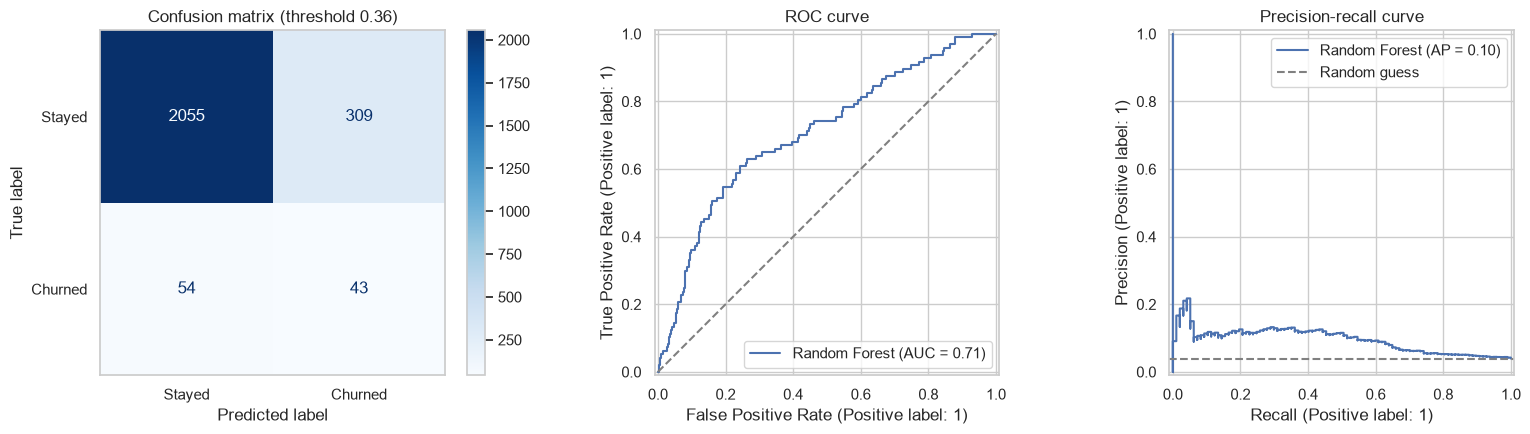

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, (test_prob >= chosen_threshold).astype(int),
    display_labels=["Stayed", "Churned"], cmap="Blues", ax=axes[0],
)
axes[0].set_title(f"Confusion matrix (threshold {chosen_threshold:.2f})")
axes[0].grid(False)

RocCurveDisplay.from_predictions(y_test, test_prob, name=best_name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1].set_title("ROC curve")

PrecisionRecallDisplay.from_predictions(y_test, test_prob, name=best_name, ax=axes[2])
axes[2].axhline(y_test.mean(), linestyle="--", color="gray", label="Random guess")
axes[2].legend()
axes[2].set_title("Precision-recall curve")
plt.tight_layout()
plt.show()

In [18]:
# Lift: how much more churn is concentrated in the members the model ranks highest.
ranked = pd.DataFrame({"prob": test_prob, "churned": y_test.to_numpy()}).sort_values("prob", ascending=False)
ranked["decile"] = np.repeat(np.arange(1, 11), int(np.ceil(len(ranked) / 10)))[: len(ranked)]
lift_table = ranked.groupby("decile").agg(
    customers=("churned", "size"),
    churners=("churned", "sum"),
    churn_rate=("churned", "mean"),
)
lift_table["lift"] = lift_table["churn_rate"] / y_test.mean()
lift_table["cumulative % of churners"] = lift_table["churners"].cumsum() / y_test.sum() * 100
display(lift_table.round(2))

,customers,churners,churn_rate,lift,cumulative % of churners
decile,,,,,
1,247,30,0.12,3.08,30.93
2,247,20,0.08,2.05,51.55
3,247,11,0.04,1.13,62.89
4,247,4,0.02,0.41,67.01
5,247,7,0.03,0.72,74.23
6,247,6,0.02,0.62,80.41
7,247,7,0.03,0.72,87.63
8,247,5,0.02,0.51,92.78
9,247,6,0.02,0.62,98.97


**Insight:** Once leakage is removed, the model's ranking is moderate (ROC-AUC about 0.7). It is still useful for a team with a fixed outreach budget: the top 20% of ranked members contain about half of all churners, around 2.5× the rate from random selection. The earlier ROC-AUC of about 0.87 was inflated by members who had already cancelled.

## Insights
Which features drive the model? Permutation importance measures how much test PR-AUC drops when each original column is shuffled. It works for any model.

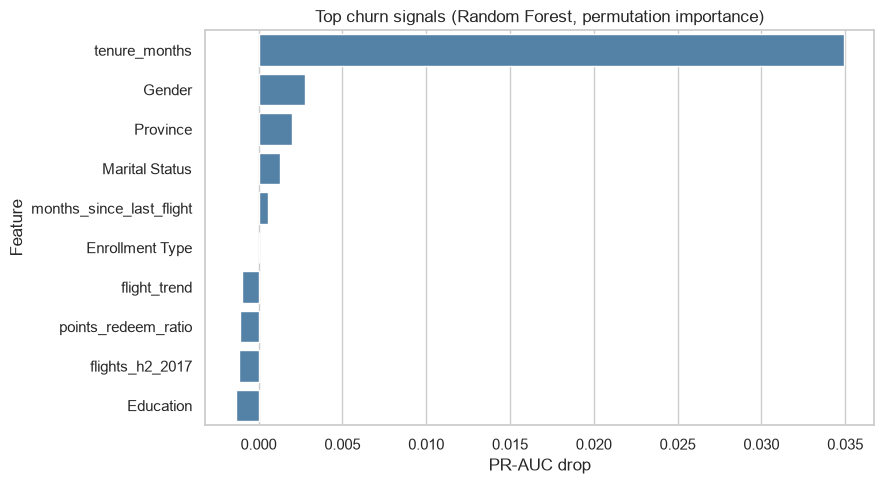

,Feature,PR-AUC drop,Std
8,tenure_months,0.0349,0.0087
1,Gender,0.0028,0.0015
0,Province,0.0020,0.0033
4,Marital Status,0.0013,0.0015
15,months_since_last_flight,0.0006,0.0011


In [19]:
importance = permutation_importance(
    best_model, X_test, y_test, scoring="average_precision",
    n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1,
)
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "PR-AUC drop": importance.importances_mean,
    "Std": importance.importances_std,
}).sort_values("PR-AUC drop", ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x="PR-AUC drop", y="Feature", data=importance_df.head(10), color="steelblue")
plt.title(f"Top churn signals ({best_name}, permutation importance)")
plt.tight_layout()
plt.show()
display(importance_df.head(5).round(4))

**Insight:** Membership tenure is by far the strongest signal. The flight-activity columns are highly correlated, so shuffling one at a time understates their combined effect. Demographics such as Gender carry little signal and should **not** be used to decide who gets an offer (fairness).

**Business action:** Treat the top signals as hypotheses for campaigns, for example a first-year onboarding offer or a re-engagement offer for members who rarely fly. Feature importance shows association, not cause, so test any offer with a control group before scaling.

## Retention prioritization
Rank members by **expected value at risk = churn probability × CLV**, so the team calls the most valuable at-risk members first. Tiers are based on rank, because `class_weight="balanced"` makes the raw probabilities higher than the true churn rate.

In [20]:
scored_customers = df.loc[X_test.index, ["Loyalty Number", "CLV"]].copy()
scored_customers["Actual churn"] = y_test
scored_customers["Churn probability"] = test_prob
scored_customers["Expected value at risk"] = scored_customers["Churn probability"] * scored_customers["CLV"]

risk_rank = scored_customers["Churn probability"].rank(pct=True)
scored_customers["Risk tier"] = pd.cut(
    risk_rank, bins=[0, 0.70, 0.90, 1.0], labels=["Low Risk", "Medium Risk", "High Risk"], include_lowest=True,
)
action_by_tier = {
    "Low Risk": "Standard engagement; no immediate offer",
    "Medium Risk": "Personalized flight deal or points offer",
    "High Risk": "Priority outreach; contact high-CLV members first",
}
scored_customers["Recommended action"] = scored_customers["Risk tier"].map(action_by_tier)
scored_customers["Contact at chosen threshold"] = scored_customers["Churn probability"] >= chosen_threshold
scored_customers = scored_customers.sort_values("Expected value at risk", ascending=False)

tier_summary = scored_customers.groupby("Risk tier", observed=True).agg(
    Customers=("Actual churn", "size"),
    **{"Observed churn rate": ("Actual churn", "mean")},
    **{"Median CLV": ("CLV", "median")},
)
tier_summary["Recommended action"] = tier_summary.index.map(action_by_tier)
display(tier_summary.round(3))

,Customers,Observed churn rate,Median CLV,Recommended action
Risk tier,,,,
Low Risk,1722,0.021,6169.385,Standard engagement; no immediate offer
Medium Risk,492,0.063,5126.410,Personalized flight deal or points offer
High Risk,247,0.121,6005.210,Priority outreach; contact high-CLV members first


## Business simulation (what-if)
All values below are **assumptions** for illustration. CLV in this dataset is in Canadian dollars, so the simulation uses CAD.

In [21]:
retained_value_share = 0.10   # assume one saved member keeps 10% of their CLV this year
retention_offer_cost = 50     # CAD per contacted member
retention_success_rate = 0.20 # share of contacted churners who are saved

def campaign_value(contacted):
    churners = contacted[contacted["Actual churn"] == 1]
    value_saved = churners["CLV"].sum() * retained_value_share * retention_success_rate
    cost = len(contacted) * retention_offer_cost
    return value_saved, cost

campaigns = {
    "High-risk tier": scored_customers[scored_customers["Risk tier"] == "High Risk"],
    "Above chosen threshold": scored_customers[scored_customers["Contact at chosen threshold"]],
    "Top 10% by value at risk": scored_customers.head(int(len(scored_customers) * 0.10)),
    "Random 10% (no model)": scored_customers.sample(frac=0.10, random_state=RANDOM_STATE),
}
roi_rows = []
for name, contacted in campaigns.items():
    value_saved, cost = campaign_value(contacted)
    roi_rows.append({
        "Campaign": name,
        "Contacted": len(contacted),
        "Churners reached": int(contacted["Actual churn"].sum()),
        "Value saved (CAD)": round(value_saved),
        "Cost (CAD)": cost,
        "Net (CAD)": round(value_saved - cost),
        # Success rate at which value saved would exactly cover the campaign cost.
        "Break-even success rate (%)": round(cost / (value_saved / retention_success_rate) * 100, 1),
    })
roi_summary = pd.DataFrame(roi_rows).set_index("Campaign")
display(roi_summary)
print("ROI is a what-if simulation using assumptions, not a forecast or actual airline result.")

,Contacted,Churners reached,Value saved (CAD),Cost (CAD),Net (CAD),Break-even success rate (%)
Campaign,,,,,,
High-risk tier,247,30,4941,12350,-7409,50.0
Above chosen threshold,352,43,6891,17600,-10709,51.1
Top 10% by value at risk,246,21,6395,12300,-5905,38.5
Random 10% (no model),246,11,1493,12300,-10807,164.7


ROI is a what-if simulation using assumptions, not a forecast or actual airline result.


**Insight:** Model-targeted campaigns reach 2–4× more churners and value than random outreach. Under these assumptions, though, a $50 offer with 20% success still loses money, because most contacted members were never going to leave.

**Business action:** Use a cheaper first touch (email, bonus points), or keep paid offers for the top value-at-risk members. Run a pilot to measure the real success rate before scaling.

In [22]:
output_dir = next(
    (folder for folder in (Path("outputs"), Path("../outputs")) if folder.is_dir()),
    Path.cwd(),
)
output_path = output_dir / "airline_churn_predictions.csv"
scored_customers.to_csv(output_path, index=False)
print(f"Saved hold-out risk scores to {output_path}.")
display(scored_customers.head(10).round({"Churn probability": 3, "Expected value at risk": 0}))

Saved hold-out risk scores to ..\outputs\airline_churn_predictions.csv.


,Loyalty Number,CLV,Actual churn,Churn probability,Expected value at risk,Risk tier,Recommended action,Contact at chosen threshold
7193,271675,44856.11,0,0.714,32024.0,High Risk,Priority outreach; contact high-CLV members first,True
12284,351296,39365.30,0,0.599,23566.0,High Risk,Priority outreach; contact high-CLV members first,True
3040,559111,41855.17,0,0.489,20472.0,High Risk,Priority outreach; contact high-CLV members first,True
7163,218538,34611.38,0,0.541,18710.0,High Risk,Priority outreach; contact high-CLV members first,True
12140,238367,24084.54,0,0.731,17613.0,High Risk,Priority outreach; contact high-CLV members first,True
2934,529544,25807.06,1,0.636,16424.0,High Risk,Priority outreach; contact high-CLV members first,True
12289,670666,41787.90,0,0.377,15738.0,Medium Risk,Personalized flight deal or points offer,True
12277,235683,38055.21,0,0.392,14934.0,Medium Risk,Personalized flight deal or points offer,True
12168,815796,25763.41,0,0.542,13954.0,High Risk,Priority outreach; contact high-CLV members first,True
12115,207543,22951.89,0,0.588,13493.0,High Risk,Priority outreach; contact high-CLV members first,True


## Limitations and next steps
- **One snapshot, one year of history.** With more data, use several snapshots (rolling windows) and validate on a later period (train on 2017 → 2018, test on 2018 → 2019).
- **Uncalibrated probabilities.** Use `CalibratedClassifierCV` if the team needs real probabilities rather than a ranking.
- **Tuning.** Use `GridSearchCV` (for example, `C` for Logistic Regression and `max_depth` / `min_samples_leaf` for Random Forest), scored on `average_precision`.
- **Uplift, not just risk.** The best members to contact are the ones an offer will change. Measure this with an A/B test.